# AMLSim 原子事件—风险事件图基线实验

## tl;dr

本笔记验证今天调整后的论文路线：**结构化交易直接形成原子事件图，风险事件由确定性算法识别，LLM 仅用于候选规则生成而不参与最终判定**。

当前三组 AMLSim 20K 数据上，`adaptive_low_value` 的节点级 F1 为 0.792–0.817，但这主要暴露了合成数据的金额可分性，不应被解释为真实反洗钱效果。语义模式基线在 fan-in 数据上有效（F1=0.755），在 cycle 数据上较弱（F1=0.205），说明下一步应实现滑动时间窗、循环专用剪枝和风险事件级对齐。

## Context & Methods

### 研究问题

1. 公开 AMLSim 数据能否被稳定转换为不泄漏标签的原子事件图？
2. 常见图规则、重复边和金额阈值基线分别能达到什么效果？
3. 通用子图匹配与面向风险模式的索引算法在效率上有多大差异？

### Key Assumptions

- `isFraud` 与 `fraudStep` 只在预测完成后用于评价，不进入特征、阈值或图模式。
- 风险事件是若干原子事件在有界时间窗内的组合；案例检索应比较风险事件图，而不是逐条原子事件硬匹配。
- 当前评价是节点级代理任务，不等同于银行生产中的案件级告警质量。
- 所有结果均来自固定下载文件与确定性脚本；随机性不是本轮误差来源。

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
METRICS = ROOT / "outputs" / "amlsim-baselines" / "metrics.csv"
QUALITY = ROOT / "outputs" / "amlsim-baselines" / "data_quality.csv"
REFERENCE = ROOT / "outputs" / "reference-algorithms" / "results.json"
ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)

metrics = pd.read_csv(METRICS)
quality = pd.read_csv(QUALITY)
reference = json.loads(REFERENCE.read_text(encoding="utf-8"))
pd.set_option("display.max_columns", None)

Matplotlib is building the font cache; this may take a moment.


## Data

IBM AMLSim 的三个官方 20K 样本分别注入 cycle、fan-in 以及两者混合模式。质量检查关注缺失值、孤立账户引用、非正金额、重复交易、自环和标签完整性。标签只保留在评价元数据中。

In [2]:
quality[[
    "dataset", "node_rows", "transaction_rows", "fraud_node_rate",
    "fraud_nodes_without_labeled_step", "exact_duplicate_transactions",
    "self_loops", "orphan_references", "min_amount", "max_amount"
]]

,dataset,node_rows,transaction_rows,fraud_node_rate,fraud_nodes_without_labeled_step,exact_duplicate_transactions,self_loops,orphan_references,min_amount,max_amount
0,20K_cycle200,20000,117805,0.04725,482,1420,14,0,10.11,599.91
1,20K_fanin200,20000,118250,0.04770,478,254,14,0,2.52,599.91
2,20K_fanin200cycle200,20000,120558,0.09020,906,1684,15,0,2.51,599.91


质量结论：三组数据均无孤立账户引用、非正金额或缺失主键；但每组都有自环和完全重复交易。更关键的是，大约一半欺诈节点没有有效 `fraudStep`，因此本轮只采用节点级 `isFraud` 标签。此外，注入的异常金额明显低于普通交易，金额基线会获得不现实的高精度，这是外部有效性的核心限制。

## Results

### 节点级基线效果

下图使用 F1（调和精确率与召回率）比较六类基线。颜色越深表示 F1 越高；单元格内显示精确值。

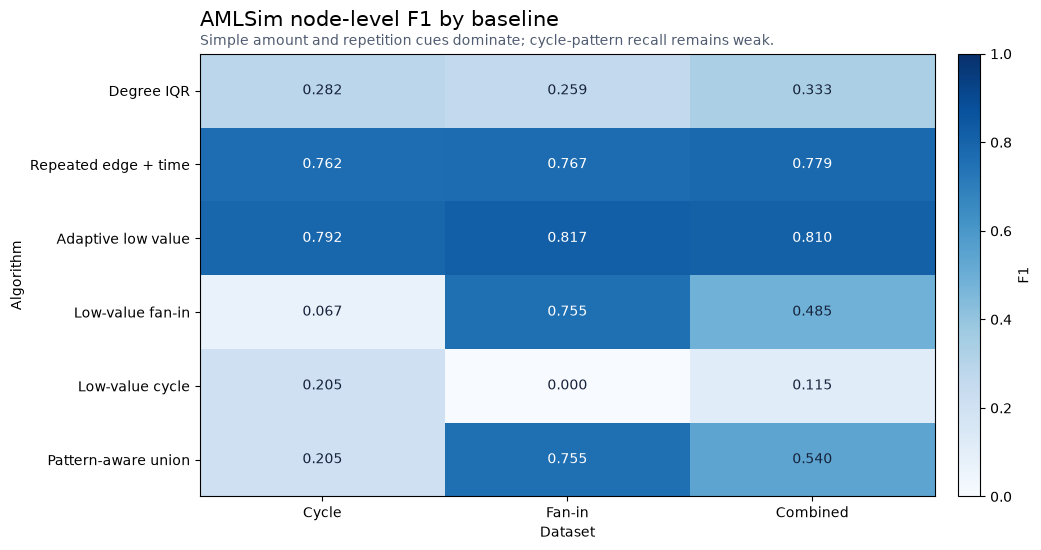

In [3]:
algorithm_order = [
    "degree_iqr", "repeated_edge_time", "adaptive_low_value",
    "low_value_fan_in", "low_value_cycle", "pattern_aware_union"
]
dataset_order = ["20K_cycle200", "20K_fanin200", "20K_fanin200cycle200"]
pivot = metrics.pivot(index="algorithm", columns="dataset", values="f1").loc[
    algorithm_order, dataset_order
]

fig, ax = plt.subplots(figsize=(10.5, 5.6))
image = ax.imshow(pivot.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(dataset_order)), ["Cycle", "Fan-in", "Combined"])
ax.set_yticks(range(len(algorithm_order)), [
    "Degree IQR", "Repeated edge + time", "Adaptive low value",
    "Low-value fan-in", "Low-value cycle", "Pattern-aware union"
])
for row in range(pivot.shape[0]):
    for col in range(pivot.shape[1]):
        value = pivot.iloc[row, col]
        ax.text(col, row, f"{value:.3f}", ha="center", va="center",
                color="white" if value > 0.55 else "#17233c", fontsize=10)
ax.set_title("AMLSim node-level F1 by baseline", loc="left", fontsize=15, pad=20)
ax.text(0, 1.02, "Simple amount and repetition cues dominate; cycle-pattern recall remains weak.",
        transform=ax.transAxes, fontsize=10, color="#4f5b70")
ax.set_xlabel("Dataset")
ax.set_ylabel("Algorithm")
fig.colorbar(image, ax=ax, fraction=0.03, pad=0.03, label="F1")
fig.tight_layout()
f1_chart = ARTIFACTS / "amlsim_baseline_f1_heatmap.png"
fig.savefig(f1_chart, dpi=180, bbox_inches="tight")
plt.show()

In [4]:
metrics.sort_values(["dataset", "f1"], ascending=[True, False])[[
    "dataset", "algorithm", "precision", "recall", "f1", "balanced_accuracy"
]]

,dataset,algorithm,precision,recall,f1,balanced_accuracy
2,20K_cycle200,adaptive_low_value,1.000000,0.655026,0.791560,0.827513
1,20K_cycle200,repeated_edge_time,1.000000,0.615873,0.762279,0.807937
0,20K_cycle200,degree_iqr,0.239499,0.343915,0.282363,0.644878
4,20K_cycle200,low_value_cycle,1.000000,0.114286,0.205128,0.557143
5,20K_cycle200,pattern_aware_union,1.000000,0.114286,0.205128,0.557143
3,20K_cycle200,low_value_fan_in,1.000000,0.034921,0.067485,0.517460
8,20K_fanin200,adaptive_low_value,1.000000,0.690776,0.817111,0.845388
7,20K_fanin200,repeated_edge_time,1.000000,0.621593,0.766645,0.810797
9,20K_fanin200,low_value_fan_in,1.000000,0.605870,0.754569,0.802935
11,20K_fanin200,pattern_aware_union,1.000000,0.605870,0.754569,0.802935


`adaptive_low_value` 在三组数据上均为最佳，但 1.0 的精确率与金额断层共同表明它利用了生成器痕迹。更适合作为论文算法起点的是 `pattern_aware_union`：它具有可解释的风险事件语义，但 cycle 召回不足，给滑动时间窗和环路剪枝留下明确改进空间。

### 通用子图匹配与模式索引效率

在 fan-in 样本前 5,000 条交易构成的图上，NetworkX VF2 枚举两源汇聚模式耗时约 23.75 秒；面向该模式的索引计数仅约 0.001 秒。二者计数口径不同（VF2 会计算源节点排列），因此这里只比较运行时间，不比较命中数量。

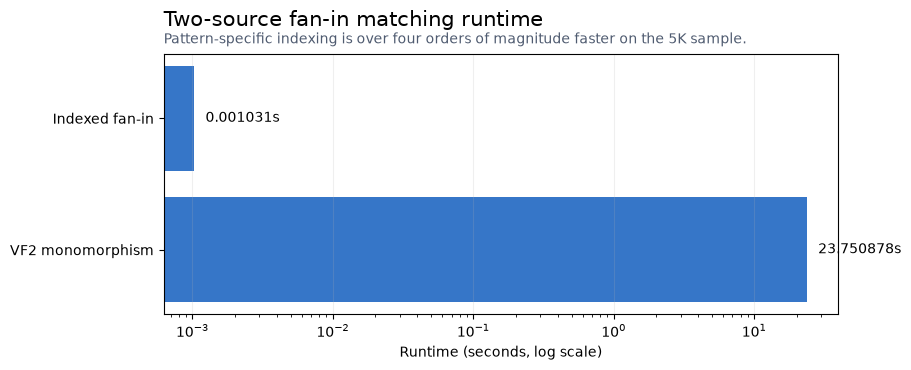

,algorithm,runtime_seconds
0,VF2 monomorphism,23.750878
1,Indexed fan-in,0.001031


In [5]:
subgraph = reference["subgraph_matching_reference"]
runtime_rows = pd.DataFrame([
    {"algorithm": "VF2 monomorphism", "runtime_seconds": subgraph["vf2_runtime_seconds"]},
    {"algorithm": "Indexed fan-in", "runtime_seconds": subgraph["indexed_runtime_seconds"]},
])

fig, ax = plt.subplots(figsize=(9.2, 3.8))
bars = ax.barh(runtime_rows["algorithm"], runtime_rows["runtime_seconds"], color="#3676c8")
ax.set_xscale("log")
ax.set_xlabel("Runtime (seconds, log scale)")
ax.set_title("Two-source fan-in matching runtime", loc="left", fontsize=15, pad=20)
ax.text(0, 1.04, "Pattern-specific indexing is over four orders of magnitude faster on the 5K sample.",
        transform=ax.transAxes, fontsize=10, color="#4f5b70")
for bar, value in zip(bars, runtime_rows["runtime_seconds"]):
    ax.text(value * 1.2, bar.get_y() + bar.get_height() / 2,
            f"{value:.6f}s", va="center", fontsize=10)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
runtime_chart = ARTIFACTS / "vf2_vs_indexed_runtime.png"
fig.savefig(runtime_chart, dpi=180, bbox_inches="tight")
plt.show()
runtime_rows

### 风险事件级图对齐参考算法

在三个风险事件的玩具案例对上，Hungarian、Sinkhorn 和 Fused Gromov–Wasserstein 均已能够运行。该结果只用于验证实现链路，样本过小，不能据此比较算法优劣。正式实验需要案件级切分和人工或合成的相似案例相关性标注。

In [6]:
transport = reference["transport_references"]
pd.DataFrame([
    {"algorithm": "Hungarian", **transport["hungarian"]},
    {"algorithm": "Sinkhorn", **transport["sinkhorn"]},
    {
        "algorithm": "Fused Gromov-Wasserstein",
        "similarity": transport["fused_gromov_wasserstein"]["similarity_proxy"],
        "runtime_seconds": transport["fused_gromov_wasserstein"]["runtime_seconds"],
    },
    {
        "algorithm": "HAMLET hierarchical",
        "similarity": transport["hamlet_hierarchical"]["similarity"],
        "runtime_seconds": np.nan,
    },
])

,algorithm,similarity,runtime_seconds
0,Hungarian,0.981768,0.000028
1,Sinkhorn,0.952538,0.000955
2,Fused Gromov-Wasserstein,0.990884,0.001315
3,HAMLET hierarchical,0.973896,NaN


## Takeaways

1. **代码需要围绕算法而非 LLM 重构。** 原子事件图、风险事件层和风险事件级相似检索方向成立；LLM 应保留为候选模式编译器，并由 DSL 校验与确定性匹配接管最终输出。
2. **论文可由三个算法模块支撑。** 推荐主线为：滑动时间窗风险事件匹配（CP-REM）、模式索引与剪枝、风险事件图的 FGW/Sinkhorn 分层对齐。
3. **不能把当前最高 F1 当作论文贡献。** 金额断层、重复交易和不完整时间标签使 AMLSim 更适合做可控消融和效率验证，不足以单独证明真实业务有效性。
4. **下一轮实验。** 为 cycle 与 fan-in 构造事件级 ground truth；加入时间窗敏感性、去重、金额扰动和跨生成配置测试；再与 VF2、规则匹配、Hungarian、Sinkhorn、FGW 做公平对比。

### Reproducibility

- 数据：IBM AMLSim 官方 20K cycle / fan-in / combined 样本；校验和记录在 `data/amlsim_checksums.sha256`。
- 基线：`PYTHONPATH=src python3 -m hamletkg.cli benchmark-amlsim --data-root data/raw/amlsim --output outputs/amlsim-baselines`。
- 参考算法：`.venv/bin/python scripts/run_reference_algorithms.py`。
- 本笔记：`.venv/bin/python scripts/build_experiment_notebook.py`。